# **Proyecto Integrador Machine Learning II — Segunda Entrega**
## **Fase 2: Datos, Flujo Reproducible sin Fuga de Información, Modelamiento y Validación**

**Integrantes:** David Castro & Alejandro Pardo  
**Asignatura:** Machine Learning II — Universidad Externado de Colombia  
**Fecha:** Octubre de 2026  

---

### **1. Carga de datos y Análisis Exploratorio (EDA)**
Cargamos el conjunto de datos de scoring crediticio adaptado al contexto colombiano (6,000 registros, 54.5% informalidad, tasa base de desbalance de mora).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('muted')

# Cargar dataset generado
df = pd.read_csv('datasets/credito_colombia_simulado.csv')
print("Dimensiones del dataset:", df.shape)
display(df.head())
display(df.info())
display(df.describe().T)

Dimensiones del dataset: (6000, 11)


,edad,es_informal,antiguedad_laboral,ingreso_smmlv,monto_credito_smmlv,plazo_meses,creditos_activos,moras_previas,score_crediticio,relacion_cuota_ingreso,incumple
0,56,1,0.4,1.70,2.39,12,0,1,541.0,0.141,0
1,69,0,1.3,2.31,3.46,12,1,0,649.0,0.150,0
2,46,1,0.3,2.16,2.54,36,2,0,726.0,0.039,0
3,32,0,8.4,1.58,8.05,12,2,0,716.0,0.509,0
4,60,1,1.3,0.75,4.28,60,0,1,532.0,0.114,0


<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   edad                    6000 non-null   int64  
 1   es_informal             6000 non-null   int64  
 2   antiguedad_laboral      5713 non-null   float64
 3   ingreso_smmlv           5759 non-null   float64
 4   monto_credito_smmlv     6000 non-null   float64
 5   plazo_meses             6000 non-null   int64  
 6   creditos_activos        6000 non-null   int64  
 7   moras_previas           6000 non-null   int64  
 8   score_crediticio        5821 non-null   float64
 9   relacion_cuota_ingreso  6000 non-null   float64
 10  incumple                6000 non-null   int64  
dtypes: float64(5), int64(6)
memory usage: 515.8 KB


None

,count,mean,std,min,25%,50%,75%,max
edad,6000.0,43.677500,14.913872,18.000,31.000,44.000,56.00,69.000
es_informal,6000.0,0.564500,0.495864,0.000,0.000,1.000,1.00,1.000
antiguedad_laboral,5713.0,3.635130,4.435433,0.000,0.800,2.100,4.60,38.900
ingreso_smmlv,5759.0,2.616301,1.673162,0.310,1.510,2.160,3.24,16.860
monto_credito_smmlv,6000.0,5.031388,3.725945,0.220,2.580,4.020,6.36,45.750
plazo_meses,6000.0,36.058000,17.047377,12.000,24.000,36.000,48.00,60.000
creditos_activos,6000.0,1.429000,1.172115,0.000,1.000,1.000,2.00,8.000
moras_previas,6000.0,0.537500,0.767263,0.000,0.000,0.000,1.00,6.000
score_crediticio,5821.0,624.594915,84.862430,340.000,566.000,626.000,684.00,850.000
relacion_cuota_ingreso,6000.0,0.117114,0.149996,0.002,0.034,0.068,0.14,2.347


### **2. Verificación de Desbalance y Diagnóstico de Calidad**

/tmp/ipykernel_4415/970557.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='incumple', ax=ax[0], palette=['#2b5c8f', '#d95f02'])
/tmp/ipykernel_4415/970557.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[0].set_xticklabels(['Al Día (0)', 'Incumple (1)'])


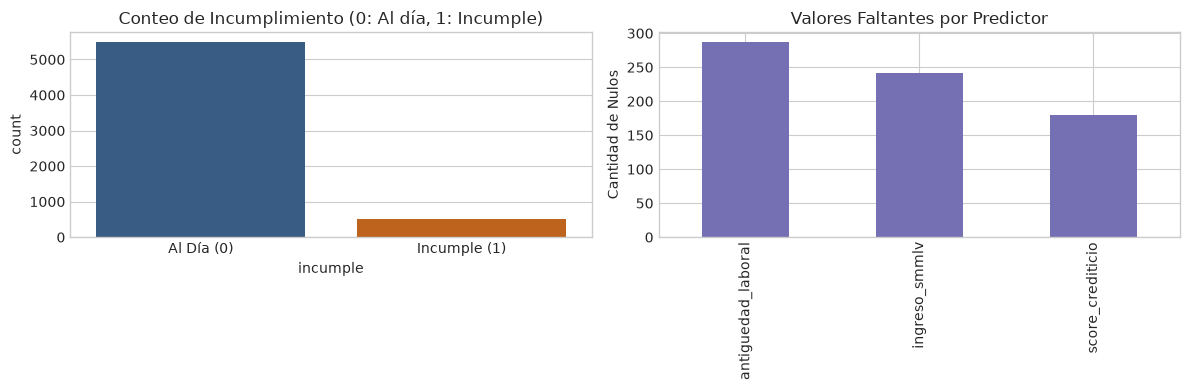

Tasa de desbalance: 8.50% de mora.


In [2]:
# Distribución de la Variable Objetivo (Desbalance de Clases)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='incumple', ax=ax[0], palette=['#2b5c8f', '#d95f02'])
ax[0].set_title('Conteo de Incumplimiento (0: Al día, 1: Incumple)')
ax[0].set_xticklabels(['Al Día (0)', 'Incumple (1)'])

null_counts = df.isnull().sum()
null_counts[null_counts > 0].plot(kind='bar', ax=ax[1], color='#7570b3')
ax[1].set_title('Valores Faltantes por Predictor')
ax[1].set_ylabel('Cantidad de Nulos')
plt.tight_layout()
plt.show()

print(f"Tasa de desbalance: {df['incumple'].mean():.2%} de mora.")

### **3. Construcción del Flujo Reproducible (Pipeline)**
Para **prevenir estrictamente la fuga de datos (Data Leakage)**, todas las transformaciones (imputación mediana y escalamiento estándar) se empaquetan en un `Pipeline` de `scikit-learn` que se ajusta dentro de cada pliegue de validación cruzada.

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Separación de predictores y variable objetivo
X = df.drop(columns=['incumple'])
y = df['incumple']

# Partición Train (80%) / Test (20%) Estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}")

Train size: 4800 | Test size: 1200


### **4. Definición, Entrenamiento y Comparación de Modelos**
Comparamos la línea base de mayoría frente a los modelos avanzados del curso y del artículo:

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix

# Definición de Modelos Candidatos
models = {
    'Baseline (Mayoría)': DummyClassifier(strategy='most_frequent'),
    'Árbol de Decisión': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest (Balanced)': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight='balanced'),
    'AdaBoost': AdaBoostClassifier(n_estimators=50, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])
    
    # Validación Cruzada de 5 pliegues
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['balanced_accuracy', 'recall', 'f1'])
    
    # Ajuste final sobre todo Train
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba') else np.zeros(len(y_test))
    
    results.append({
        'Modelo': name,
        'CV Balanced Acc (Media)': cv_res['test_balanced_accuracy'].mean(),
        'CV Balanced Acc (Desv)': cv_res['test_balanced_accuracy'].std(),
        'Test Balanced Acc': balanced_accuracy_score(y_test, y_pred),
        'Test Recall (Incumplimiento)': recall_score(y_test, y_pred, zero_division=0),
        'Test Precision': precision_score(y_test, y_pred, zero_division=0),
        'Test F1-score': f1_score(y_test, y_pred, zero_division=0),
        'Test ROC-AUC': roc_auc_score(y_test, y_proba) if hasattr(pipe, 'predict_proba') else 0.5
    })

res_df = pd.DataFrame(results)
display(res_df)

,Modelo,CV Balanced Acc (Media),CV Balanced Acc (Desv),Test Balanced Acc,Test Recall (Incumplimiento),Test Precision,Test F1-score,Test ROC-AUC
0,Baseline (Mayoría),0.500000,0.000000,0.500000,0.000000,0.000000,0.000000,0.500000
1,Árbol de Decisión,0.716893,0.051225,0.727794,0.490196,0.568182,0.526316,0.908394
2,Random Forest (Balanced),0.875204,0.026601,0.862584,0.823529,0.437500,0.571429,0.946453
3,AdaBoost,0.759425,0.017181,0.712392,0.441176,0.714286,0.545455,0.947132
4,Gradient Boosting,0.770415,0.029619,0.754688,0.529412,0.710526,0.606742,0.949962


### **5. Ajuste de Hiperparámetros (GridSearchCV) para Random Forest**

In [5]:
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [6, 8, 12],
    'classifier__min_samples_split': [2, 5],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

rf_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

grid_search = GridSearchCV(
    rf_pipe, param_grid, cv=cv, scoring='balanced_accuracy', n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Mejores Hiperparámetros:", grid_search.best_params_)
best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)
print(f"Test Balanced Accuracy (RF Optimizado): {balanced_accuracy_score(y_test, y_pred_best):.4f}")
print(f"Test Recall (RF Optimizado): {recall_score(y_test, y_pred_best):.4f}")

Mejores Hiperparámetros: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 6, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Test Balanced Accuracy (RF Optimizado): 0.8659
Test Recall (RF Optimizado): 0.8529


### **6. Matriz de Confusión e Importancia de Variables (Feature Importance)**

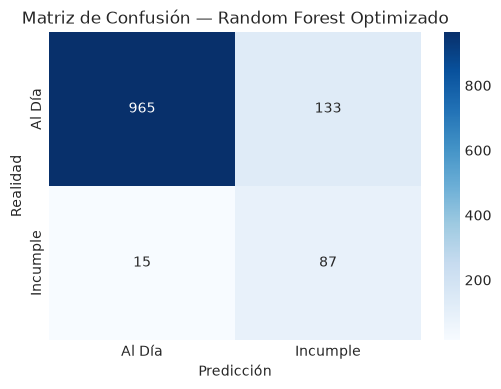

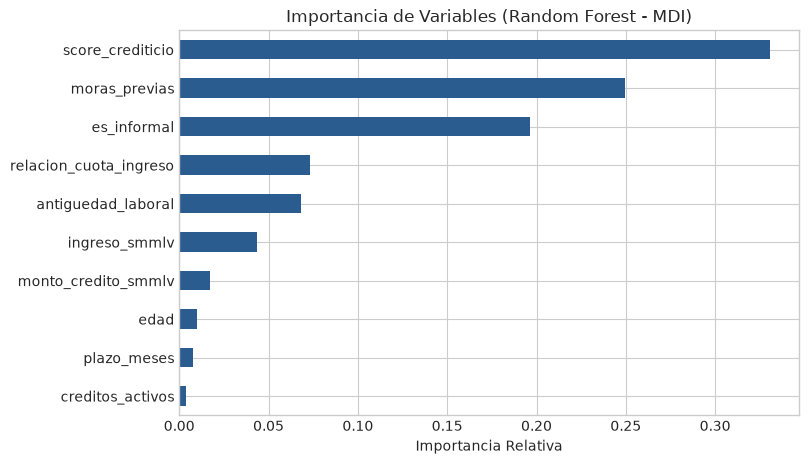

In [6]:
# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Al Día', 'Incumple'], yticklabels=['Al Día', 'Incumple'])
plt.title('Matriz de Confusión — Random Forest Optimizado')
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

# Importancia de Variables
rf_model = best_rf.named_steps['classifier']
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#2b5c8f')
plt.title('Importancia de Variables (Random Forest - MDI)')
plt.xlabel('Importancia Relativa')
plt.show()